[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Laverde97/phd-data-science-ai/blob/main/semesters/semester-01/deep-learning-1/week-02/class-02/notebooks/Guia_Redes_Neuronales_Practicas.ipynb)

# Redes neuronales artificiales — laboratorio reproducible

**Complemento del PDF «Redes neuronales artificiales: de la intuición al funcionamiento matemático y su implementación en Python»**  
**Nivel:** introductorio / intermedio · **Entorno:** Jupyter, VS Code o Google Colab.

Este cuaderno explica con experimentos: (1) qué hace una neurona, (2) cómo funcionan las activaciones y softmax, (3) cómo se calcula una actualización de *backpropagation*, (4) cómo entrenar desde cero con NumPy y (5) cómo entrenar un MLP con PyTorch y `DataLoader`.

Los conjuntos de datos de clasificación son **sintéticos y exclusivamente didácticos**. Los resultados dependen del entorno y no representan desempeño en aplicaciones reales.

> En Google Colab, normalmente ya están disponibles NumPy, Matplotlib, scikit-learn y PyTorch. Si falta alguno en tu entorno, instala solo esa dependencia.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import torch

np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(2)
print('NumPy:', np.__version__, '| sklearn:', sklearn.__version__, '| torch:', torch.__version__)

NumPy: 2.3.5 | sklearn: 1.8.0 | torch: 2.10.0+cpu


## 1. Una neurona: combinación lineal y sigmoide

Una neurona combina entradas con pesos: $z=\mathbf w^T\mathbf x+b$ y luego aplica una función $\phi(z)$. Con sigmoide, el resultado está entre 0 y 1.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

x = np.array([0.35, 0.70])
w = np.array([0.20, 0.30])
b = -0.10
z = np.dot(x, w) + b
print('z =', round(z, 4), '| sigmoid(z) =', round(float(sigmoid(z)), 4))
assert np.isclose(z, 0.18)
assert np.isclose(sigmoid(z), 0.5448788924)

z = 0.18 | sigmoid(z) = 0.5449


## 2. Gráficas de activación y ejemplo de softmax

La activación lineal preserva el valor; sigmoide comprime entre 0 y 1; tanh entre −1 y 1; y ReLU conserva los positivos y trunca los negativos. Softmax transforma un vector de logits en probabilidades normalizadas.

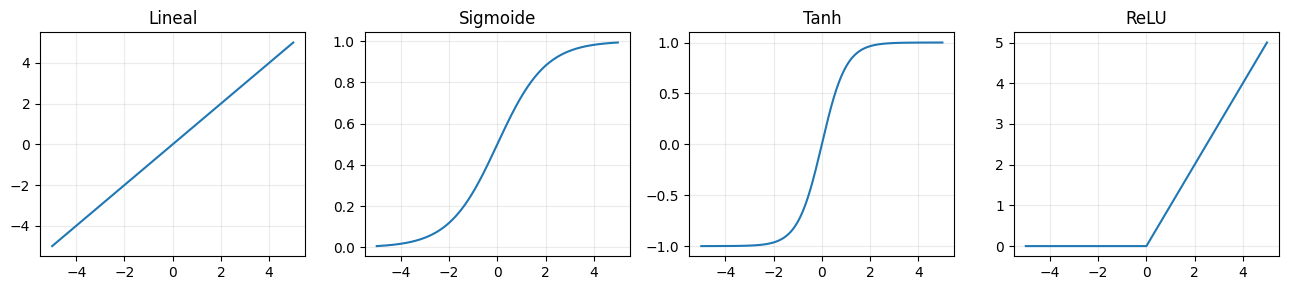

Softmax = [0.659  0.2424 0.0986] | Suma = 1.0


In [3]:
z_grid = np.linspace(-5, 5, 401)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, (name, fn) in zip(axs, [('Lineal', lambda z:z), ('Sigmoide', sigmoid), ('Tanh', np.tanh), ('ReLU', lambda z:np.maximum(z, 0))]):
    ax.plot(z_grid, fn(z_grid)); ax.set_title(name); ax.grid(alpha=.25)
plt.tight_layout(); plt.show()

logits = np.array([2., 1., 0.1])
e = np.exp(logits - np.max(logits))
prob = e / e.sum()
print('Softmax =', np.round(prob, 4), '| Suma =', prob.sum())
assert np.isclose(prob.sum(), 1)

## 3. Forward y backpropagation: el ejemplo de la presentación

Entrada $x=(0.35, 0.70)$, dos neuronas ocultas con sigmoide, objetivo $y=0.50$ y pérdida $\frac{1}{2}(\hat y-y)^2$. Usaremos las mismas ponderaciones del desarrollo paso a paso. Aquí $\delta$ es el gradiente con signo $\hat y-y$, por lo que la actualización **resta** el gradiente.

In [4]:
x = np.array([0.35, 0.70]); y_target = 0.50
W1 = np.array([[0.20, 0.20], [0.30, 0.30]])
W2 = np.array([0.30, 0.90])
h = sigmoid(W1 @ x)
y_pred = float(sigmoid(W2 @ h))
loss_before = 0.5 * (y_pred - y_target)**2

delta_out = (y_pred - y_target) * y_pred * (1 - y_pred)
delta_h = h * (1 - h) * W2 * delta_out
G2 = delta_out * h
G1 = np.outer(delta_h, x)
eta = 1.0
W1_new = W1 - eta * G1
W2_new = W2 - eta * G2
new_pred = float(sigmoid(W2_new @ sigmoid(W1_new @ x)))
loss_after = 0.5 * (new_pred - y_target)**2
print('Activaciones ocultas:', np.round(h, 5))
print('Prediccion inicial:', round(y_pred, 6))
print('Pérdida inicial:', round(loss_before, 8))
print('Delta salida:', round(delta_out, 8), 'Delta ocultas:', np.round(delta_h, 8))
print('W1 nuevos:\n', np.round(W1_new, 5))
print('W2 nuevos:', np.round(W2_new, 5))
print('Pérdida tras actualizar:', round(loss_after, 8))
assert np.isclose(y_pred, 0.66507363952)
assert np.isclose(W2_new[0], 0.27969149)
assert loss_after < loss_before

Activaciones ocultas: [0.55231 0.57811]
Prediccion inicial: 0.665074
Pérdida inicial: 0.01362465
Delta salida: 0.03677027 Delta ocultas: [0.00272759 0.00807143]
W1 nuevos:
 [[0.19905 0.19809]
 [0.29718 0.29435]]
W2 nuevos: [0.27969 0.87874]
Pérdida tras actualizar: 0.0127287


### Validar gradientes: diferencias finitas

La derivación analítica puede comprobarse aproximando $\partial\mathcal L/\partial w$ con $[\mathcal L(w+\epsilon)-\mathcal L(w-\epsilon)]/(2\epsilon)$. Es una técnica diagnóstica llamada *gradient checking*.

In [5]:
def manual_loss(w1, w2):
    output = sigmoid(w2 @ sigmoid(w1 @ x))
    return 0.5 * (output - y_target)**2

eps = 1e-5
W2_plus, W2_minus = W2.copy(), W2.copy()
W2_plus[0] += eps
W2_minus[0] -= eps
numeric_grad = (manual_loss(W1, W2_plus) - manual_loss(W1, W2_minus))/(2*eps)
print('Gradiente analítico w35:', round(G2[0], 9))
print('Gradiente numérico w35:', round(numeric_grad, 9))
assert np.isclose(numeric_grad, G2[0], atol=1e-8)

Gradiente analítico w35: 0.02030851
Gradiente numérico w35: 0.02030851


## 4. Regresión logística binaria desde cero con NumPy

Este experimento genera datos sintéticos y reserva 20% para prueba. Para simplificar, la regresión logística está implementada con operaciones matriciales, sin usar `sklearn.linear_model`. Entrenamiento y evaluación se muestran por separado.

Accuracy de prueba: 0.93
Precision: 0.945
Recall: 0.929
F1: 0.937


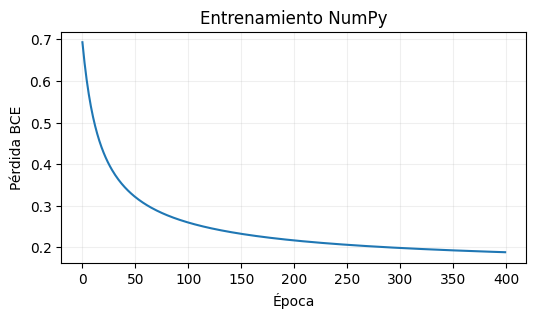

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

rng = np.random.default_rng(42)
X = rng.normal(size=(500, 2))
logits_true = X @ np.array([1.5, -2.0]) + 0.4 + rng.normal(0, .5, 500)
y = (logits_true > 0).astype(float)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)

w = np.zeros(2); b = 0.; history = []
for epoch in range(400):
    p = sigmoid(X_tr @ w + b)
    p_safe = np.clip(p, 1e-12, 1-1e-12)
    loss = -np.mean(y_tr*np.log(p_safe) + (1-y_tr)*np.log(1-p_safe))
    history.append(loss)
    dw = X_tr.T @ (p-y_tr) / len(y_tr)
    db = (p-y_tr).mean()
    w -= 0.2*dw; b -= 0.2*db

prediction = (sigmoid(X_te @ w + b) >= .5).astype(int)
print('Accuracy de prueba:', round(accuracy_score(y_te, prediction), 3))
print('Precision:', round(precision_score(y_te, prediction), 3))
print('Recall:', round(recall_score(y_te, prediction), 3))
print('F1:', round(f1_score(y_te, prediction), 3))
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(history); ax.set(xlabel='Época', ylabel='Pérdida BCE', title='Entrenamiento NumPy'); ax.grid(alpha=.2)
plt.show()
assert history[-1] < history[0]

## 5. MLP con PyTorch y `DataLoader`

Creamos dos clases en forma de medialuna. Usaremos `nn.Linear(2, 16)`, ReLU, `nn.Linear(16, 1)`, pérdida `BCEWithLogitsLoss` y optimizador Adam.

**Atención:** no agregamos `nn.Sigmoid()` dentro del modelo porque la función de pérdida ya recibe logits.

In [7]:
from sklearn.datasets import make_moons
from sklearn.metrics import confusion_matrix, classification_report
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
X, y = make_moons(n_samples=1000, noise=.20, random_state=42)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_tr)
X_tr, X_te = scaler.transform(X_tr), scaler.transform(X_te)
train_ds = TensorDataset(torch.tensor(X_tr, dtype=torch.float32),
                         torch.tensor(y_tr, dtype=torch.float32).unsqueeze(1))
loader = DataLoader(train_ds, batch_size=32, shuffle=True)

model = nn.Sequential(nn.Linear(2,16), nn.ReLU(), nn.Linear(16,1))
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=.01)
losses = []
for epoch in range(150):
    model.train(); running = 0
    for xb, yb in loader:
        optimizer.zero_grad()
        logits = model(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        running += loss.item()*len(xb)
    losses.append(running/len(train_ds))

model.eval()
with torch.no_grad():
    probabilities = torch.sigmoid(model(torch.tensor(X_te, dtype=torch.float32))).numpy().ravel()
pred = (probabilities >= .5).astype(int)
print('Parámetros entrenables:', sum(p.numel() for p in model.parameters()))
print('Accuracy de prueba:', round(accuracy_score(y_te,pred),3))
print('Matriz de confusión:\n', confusion_matrix(y_te,pred))
print(classification_report(y_te, pred))
assert sum(p.numel() for p in model.parameters()) == 65
assert losses[-1] < losses[0]

Parámetros entrenables: 65
Accuracy de prueba: 0.995
Matriz de confusión:
 [[ 99   1]
 [  0 100]]
              precision    recall  f1-score   support

           0       1.00      0.99      0.99       100
           1       0.99      1.00      1.00       100

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



### Visualizar el entrenamiento y la frontera de decisión

La frontera es una región que el modelo aprende y sobre la que asigna probabilidades. Los puntos son datos de prueba no utilizados para ajustar los pesos.

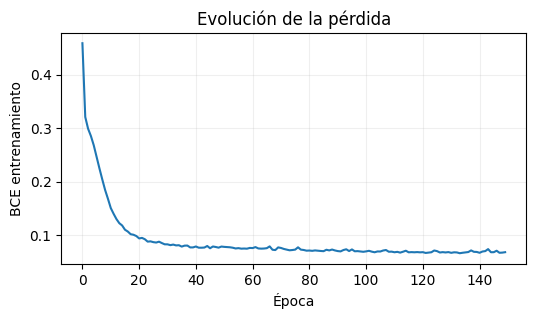

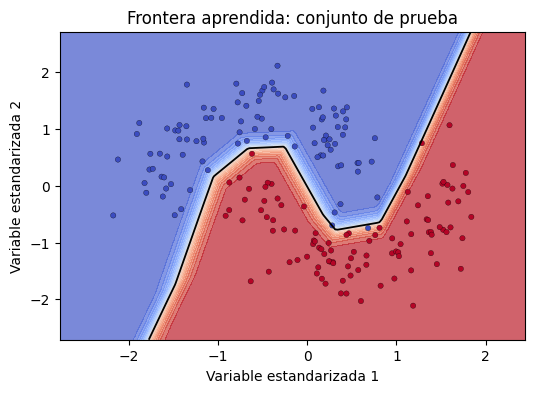

In [8]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(losses); ax.set(xlabel='Época', ylabel='BCE entrenamiento', title='Evolución de la pérdida'); ax.grid(alpha=.2)
plt.show()

xx, yy = np.meshgrid(np.linspace(X_te[:,0].min()-.6, X_te[:,0].max()+.6, 180),
                     np.linspace(X_te[:,1].min()-.6, X_te[:,1].max()+.6, 180))
xy = np.column_stack([xx.ravel(), yy.ravel()])
with torch.no_grad():
    pp = torch.sigmoid(model(torch.tensor(xy,dtype=torch.float32))).numpy().reshape(xx.shape)
fig, ax = plt.subplots(figsize=(6, 4))
ax.contourf(xx, yy, pp, levels=20, cmap='coolwarm', alpha=.7)
ax.contour(xx, yy, pp, levels=[.5], colors='black', linewidths=1.3)
ax.scatter(X_te[:,0], X_te[:,1], c=y_te, cmap='coolwarm', s=15, edgecolor='k', linewidth=.2)
ax.set(title='Frontera aprendida: conjunto de prueba', xlabel='Variable estandarizada 1', ylabel='Variable estandarizada 2')
plt.show()

## 6. Ejercicios de experimentación

1. En la neurona inicial, cambia el sesgo de $-0.1$ a $+0.5$. ¿Cómo cambia la sigmoide?
2. En el ejemplo de backpropagation, reduce la tasa $\eta$ de 1 a 0.1. ¿Qué sucede con la magnitud de actualización?
3. En PyTorch, cambia la capa de 16 neuronas por 2, 8 y 64. **Usa validación** para elegir la arquitectura, dejando el conjunto de prueba para la evaluación final.
4. Repite el entrenamiento con otra semilla. ¿Por qué no da un resultado exactamente igual?
5. Cambia el umbral de 0.5 a 0.3 y 0.7. Compara precisión y recall sin modificar los pesos.

### Recomendación de uso

Para aprender, ejecuta cada celda en orden, intenta explicar la salida antes de verla y modifica **una decisión a la vez**. Esta es una práctica educativa: no usar para decisiones de alto impacto.